In [1]:
import numpy as np
import matplotlib.pylab as plt

In [3]:
size = 4
rank = 0
arr = np.zeros(5)

indices = np.zeros(size+1)

for i in range(size):
    indices[i] = 5 * rank / size
    print(str(indices[i]) + " ")

0.0 
0.0 
0.0 
0.0 


4


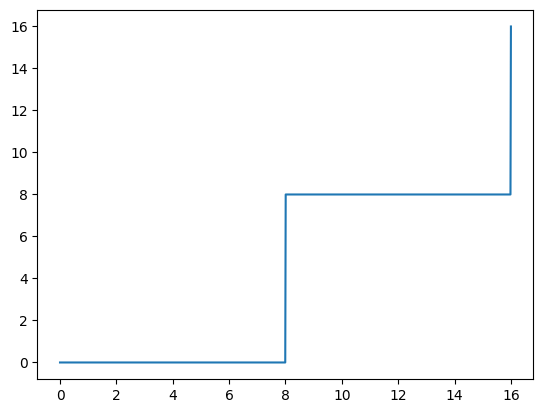

3


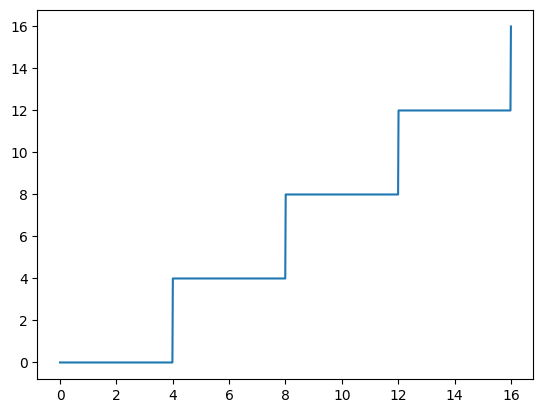

2


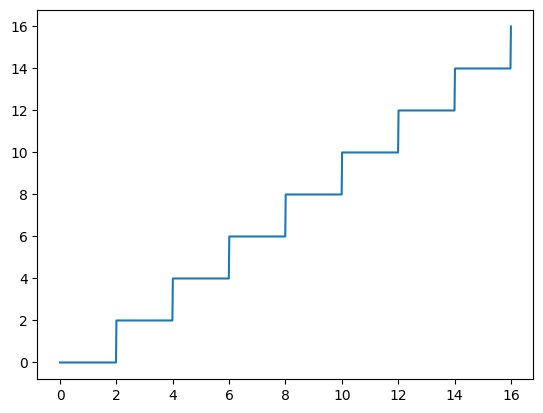

1


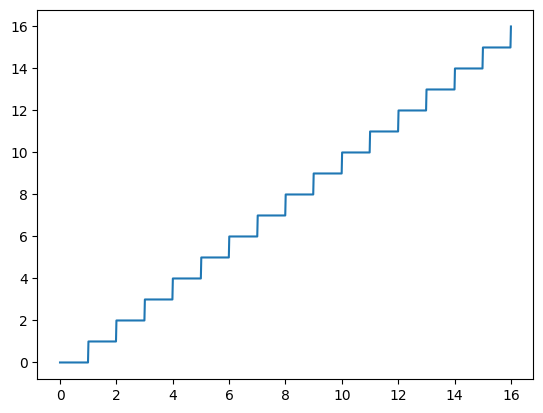

In [6]:
from ipywidgets import interact,fixed
import ipywidgets as widgets

import math

def plotStartBlock(iteration, size):
    x = np.linspace(0, size, 1000)
    blockstart = (x // 2**(iteration-1)) * 2**(iteration-1)
    plt.plot(x, blockstart)


p = 16
for i in range(int(math.log2(p)), 0, -1):
    print(i)
    plotStartBlock(i, p)
    plt.show()

In [38]:
# finding contributing processors for each iteration in reduce scatter phase using mostly halfing scheme

def nearestPow2(p):
    count = 0
    while p > 1:
        p >>=1
        count +=1
    return 1 << count

nIterations = int(np.ceil(np.log2(p)))
data = -np.ones((p,p), dtype=int)
data[:,0] = np.arange(p)
p=10
s_old = p
s = nearestPow2(p)
i = 0
while s > 0:
    print(s)
    data[0:s_old-s,i+1:p] = data[s:s_old, 0:p-i-1]
    s_old = s
    s = s//2
    i +=1
data

8
4
2
1


array([[ 0,  8,  4,  2,  1,  9,  5,  3, -1,  7],
       [ 1,  9,  5,  3, -1,  7, -1, -1, -1, -1],
       [ 2, -1,  6, -1, -1, -1, -1, -1, -1, -1],
       [ 3, -1,  7, -1, -1, -1, -1, -1, -1, -1],
       [ 4, -1, -1, -1, -1, -1, -1, -1, -1, -1],
       [ 5, -1, -1, -1, -1, -1, -1, -1, -1, -1],
       [ 6, -1, -1, -1, -1, -1, -1, -1, -1, -1],
       [ 7, -1, -1, -1, -1, -1, -1, -1, -1, -1],
       [ 8, -1, -1, -1, -1, -1, -1, -1, -1, -1],
       [ 9, -1, -1, -1, -1, -1, -1, -1, -1, -1]])